# 04 – Choosing each kernel's setting

**Aim.** For every kernel, choose the setting (width σ or polynomial degree) that gives the best
cross-validated **balanced kNN accuracy** on the kPC scores, so that the kernels are compared fairly in
notebook 05. The chosen settings are used for the biplots there.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import kpca_tools as kt

FIG_DIR = "figures"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

X_raw, y = kt.load_meter_b()
X = X_raw[:, np.setdiff1d(np.arange(X_raw.shape[1]), kt.constant_columns(X_raw))]   # same as notebook 01
print("X (unscaled; scaling happens inside each fold):", X.shape)

X (unscaled; scaling happens inside each fold): (92, 51)


## 1. Method

**Why the class labels are needed.** kPCA has no built-in measure of a good setting: explained variance
cannot choose σ (a tiny σ spreads variance evenly over many kPCs, a huge σ makes the Gaussian kernel almost
linear). Our question is class discrimination, so the setting is chosen by how well the classes can be
told apart in kPC space. This is supervised calibration, as in Duma et al. (2026), who tune kernel
parameters with a discrimination objective and state that this departs from unsupervised kPCA.

**Criterion.** Balanced accuracy (mean of the per-class recalls, so the large waxing class cannot dominate)
of a k-nearest-neighbour classifier (k = 5) on the first q kPC scores. **q = 2 decides**, because the
biplots are two-dimensional; q = 3 and q = 7 are reported. The kNN uses the scores as they are, so it sees
exactly the geometry of the score plots.

**Grouped cross-validation.** The rows of the data file are blocks of repeated test points at the same
flow velocity (section 2), so neighbouring rows are near-duplicates. If one of them is in the training set
and its twin in the test set, the test is too easy. We therefore keep each **operating-point group** (consecutive
rows of the same class whose average flow velocity differs by at most 0.1 m/s) together: a whole group is
either in training or in test. We use stratified group 5-fold CV (`StratifiedGroupKFold`), repeated 10 times
with a different shuffle (seed 0 … 9) → 50 train/test splits per setting. Within one repeat every sample is
tested once, so 10 times in total. Every setting uses the *same* splits. In each fold, everything is fitted
on the training samples only:
1. z-scoring (`zscore`, std with n − 1); test samples are scaled with the training mean and std,
2. σ = factor × median distance of the training samples (Gaussian, Cauchy),
3. kPCA on the training kernel matrix; test samples are projected through their kernel values against the
   training samples (centred with the training statistics),
4. kNN fitted on the training scores, evaluated on the test scores.

**Grid.** σ = median distance × 2^k, k = −4 … 4 (17 values) for Gaussian and Cauchy; degree d = 1 … 5
(γ = 1/p, c = 1) for the polynomial kernel; the linear kernel has no setting.

**Selection rule (per kernel, q = 2).** Take the best mean accuracy; its standard error is the std of the
50 split scores / √50. Among all settings within one standard error of the best, take the *smoothest*
(largest σ, lowest degree), which is least likely to fit noise in 92 samples.

**Comparison.** Section 8 repeats the whole grid with ordinary (random) stratified CV, as used in the first
version of this notebook, to show how much the near-duplicates inflated the scores.

**Limitation.** Choosing a setting and reporting its score from the same CV makes that score slightly
optimistic; nested CV would remove this bias. Also, the standard error treats the 50 split scores as
independent, but the 10 repeats reuse the same 92 samples, so the true uncertainty is somewhat larger:
differences of one or two standard errors between settings should be read as "equal within uncertainty".

## 2. Operating-point groups
The average flow velocity of every row, in file order. Rows within a class come in blocks at a constant
velocity (repeated test points) and in sweeps over several velocities.

Healthy         8 groups, sizes [2, 6, 1, 1, 1, 6, 1, 1]
Gas injection   9 groups, sizes [4, 2, 1, 3, 1, 1, 2, 2, 8]
Waxing         22 groups, sizes [1, 1, 6, 6, 2, 1, 1, 2, 4, 1, 1, 1, 5, 1, 1, 1, 2, 2, 1, 1, 1, 7]

Healthy        consecutive rows  0.38  vs random order  2.15  (share of random orders this close: 0.000)
Gas injection  consecutive rows  6.30  vs random order 10.30  (share of random orders this close: 0.000)
Waxing         consecutive rows  1.55  vs random order  7.16  (share of random orders this close: 0.000)


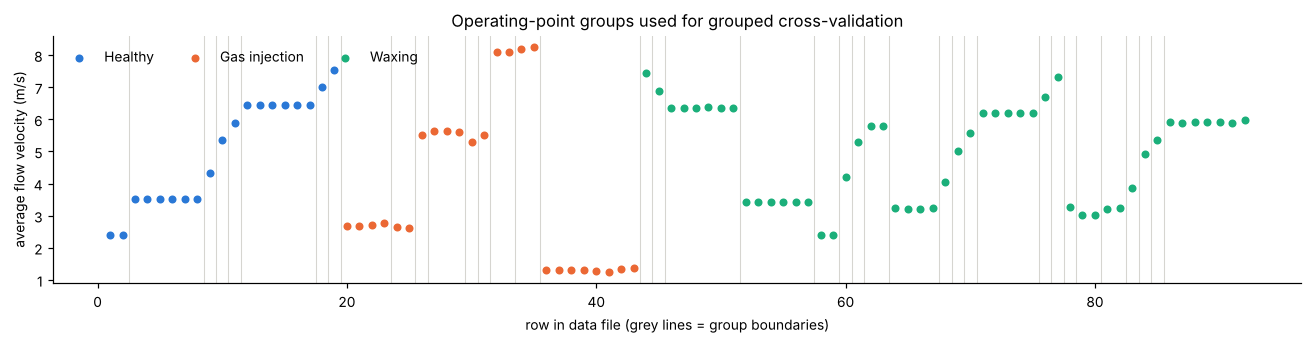

In [2]:
G = kt.operating_point_groups(X_raw, y, tol=0.1)
flow = X_raw[:, kt.FEATURE_NAMES.index("Average flow velocity")]

for c in kt.CLASS_NAMES:
    sizes = [int((G == g).sum()) for g in np.unique(G[y == c])]
    print(f"{kt.CLASS_NAMES[c]:<14} {len(sizes):2d} groups, sizes {sizes}")

# are neighbouring rows more alike than random pairs? (mean distance between consecutive rows)
Z_full, _, _ = kt.zscore(X)
rng = np.random.default_rng(0)
print()
for c in kt.CLASS_NAMES:
    Zc = Z_full[y == c]
    d_next = np.linalg.norm(np.diff(Zc, axis=0), axis=1).mean()
    d_rand = np.array([np.linalg.norm(np.diff(Zc[rng.permutation(len(Zc))], axis=0), axis=1).mean()
                       for _ in range(2000)])
    print(f"{kt.CLASS_NAMES[c]:<14} consecutive rows {d_next:5.2f}  vs random order {d_rand.mean():5.2f}"
          f"  (share of random orders this close: {np.mean(d_rand <= d_next):.3f})")

fig, ax = plt.subplots(figsize=(12, 3.2))
for c in kt.CLASS_NAMES:
    m = y == c
    ax.scatter(np.where(m)[0] + 1, flow[m], s=18, color=kt.CLASS_COLORS[c], label=kt.CLASS_NAMES[c], zorder=3)
for b in np.where(np.diff(G))[0] + 1.5:
    ax.axvline(b, color="#d6d5d0", lw=0.7, zorder=1)
ax.set_xlabel("row in data file (grey lines = group boundaries)")
ax.set_ylabel("average flow velocity (m/s)")
ax.legend(frameon=False, ncol=3, loc="upper left")
ax.set_title("Operating-point groups used for grouped cross-validation")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/m4_groups.png")
plt.show()

## 3. Cross-validation over the grid

In [3]:
Q = (2, 3, 7)
factors = 2.0 ** np.arange(-4, 5)     # sigma / median distance
degrees = [1, 2, 3, 4, 5]

GRID = {   # kernel: list of (setting label, value, arguments); listed from smoothest to least smooth
    "Linear":   [("–", None, dict(kind="linear"))],
    "Poly":     [(f"d={d}", d, dict(kind="poly", degree=d)) for d in degrees],
    "Gaussian": [(f"{f:g}", f, dict(kind="rbf", factor=f)) for f in factors[::-1]],
    "Cauchy":   [(f"{f:g}", f, dict(kind="cauchy", factor=f)) for f in factors[::-1]],
}

cv, cv_random = {}, {}   # (kernel, label) -> results; grouped CV decides, random CV only for comparison
for kernel, settings in GRID.items():
    for label, value, args in settings:
        scores, conf, wrong = kt.cv_balanced_accuracy(X, y, **args, n_comp=Q, groups=G)
        cv[(kernel, label)] = dict(value=value, scores=scores, conf=conf, wrong=wrong)
        cv_random[(kernel, label)] = kt.cv_balanced_accuracy(X, y, **args, n_comp=Q)[0]
print(f"Evaluated {len(cv)} settings x 50 train/test splits (5 folds x 10 repeats), grouped and random.")

def mean_se(s):
    return s.mean(), s.std(ddof=1) / np.sqrt(len(s))

Evaluated 24 settings x 50 train/test splits (5 folds x 10 repeats), grouped and random.


## 4. Checks

In [4]:
# (a) polynomial d = 1 is (gamma x'y + 1): centring removes the constant and gamma only rescales the
#     scores, which kNN ignores -> must give exactly the linear kernel's results
for q in Q:
    assert np.array_equal(cv[("Poly", "d=1")]["scores"][q], cv[("Linear", "–")]["scores"][q])

# (b) no group is split between training and test, and every fold contains all three classes
for tr, te in kt.cv_splits(y, G):
    assert not set(G[tr]) & set(G[te])
    assert len(np.unique(y[tr])) == 3 and len(np.unique(y[te])) == 3

# (c) same seed -> same result
again = kt.cv_balanced_accuracy(X, y, kind="rbf", factor=1.0, n_comp=Q, groups=G)[0]
assert all(np.array_equal(again[q], cv[("Gaussian", "1")]["scores"][q]) for q in Q)

print("All CV checks passed.")

All CV checks passed.


## 5. Choosing the setting for each kernel (q = 2, grouped CV)

In [5]:
chosen = {}
for kernel, settings in GRID.items():
    stats = [(label, *mean_se(cv[(kernel, label)]["scores"][2])) for label, _, _ in settings]
    best_mean, best_se = max(stats, key=lambda s: s[1])[1:]
    # settings are listed from smoothest to least smooth, so the first one within 1 SE is the smoothest
    label = next(l for l, m, _ in stats if m >= best_mean - best_se)
    chosen[kernel] = label
    print(f"{kernel:<9} best mean {best_mean:.3f} (SE {best_se:.3f}) -> chosen setting: {label}")

Linear    best mean 0.961 (SE 0.011) -> chosen setting: –
Poly      best mean 0.961 (SE 0.011) -> chosen setting: d=1
Gaussian  best mean 0.963 (SE 0.011) -> chosen setting: 16
Cauchy    best mean 0.963 (SE 0.011) -> chosen setting: 16


## 6. Accuracy against the setting (grouped CV)
Mean balanced accuracy with a band of ±1 standard error, for q = 2 (decides), 3 and 7. The dashed grey line
is the linear kernel (q = 2); the ring marks the chosen setting.

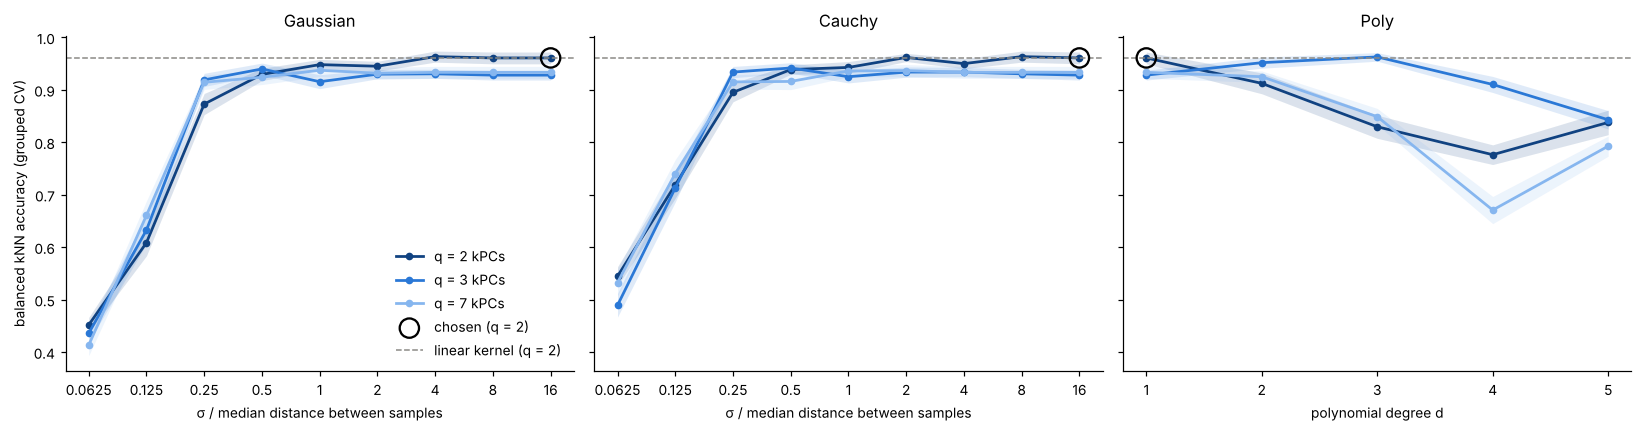

In [6]:
Q_COLORS = {2: "#104281", 3: "#2a78d6", 7: "#86b6ef"}   # one hue, darker = the q that decides
lin2 = cv[("Linear", "–")]["scores"][2].mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, kernel in zip(axes, ["Gaussian", "Cauchy", "Poly"]):
    settings = sorted(GRID[kernel], key=lambda s: s[1])
    x = np.array([v for _, v, _ in settings], dtype=float)
    for q in Q:
        ms = np.array([mean_se(cv[(kernel, l)]["scores"][q]) for l, _, _ in settings])
        ax.plot(x, ms[:, 0], marker="o", ms=4, lw=1.8, color=Q_COLORS[q], label=f"q = {q} kPCs")
        ax.fill_between(x, ms[:, 0] - ms[:, 1], ms[:, 0] + ms[:, 1], color=Q_COLORS[q], alpha=0.15, lw=0)
    v = cv[(kernel, chosen[kernel])]["value"]
    ax.scatter([v], [cv[(kernel, chosen[kernel])]["scores"][2].mean()], s=160, facecolor="none",
               edgecolor="k", lw=1.5, zorder=5, label="chosen (q = 2)")
    ax.axhline(lin2, color="#8b8a86", ls="--", lw=1, label="linear kernel (q = 2)")
    if kernel == "Poly":
        ax.set_xticks(x)
        ax.set_xlabel("polynomial degree d")
    else:
        ax.set_xscale("log", base=2)
        ax.set_xticks(x, [f"{f:g}" for f in x])
        ax.set_xlabel("σ / median distance between samples")
    ax.set_title(kernel)
axes[0].set_ylabel("balanced kNN accuracy (grouped CV)")
axes[0].legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/m4_accuracy_curves.png")
plt.show()

## 7. All results, grouped CV (mean ± standard error over the 50 train/test splits)

In [7]:
print(f"{'kernel':<9}{'setting':>8}" + "".join(f"{'q = ' + str(q):>17}" for q in Q))
for (kernel, label), r in cv.items():
    row = f"{kernel:<9}{label:>8}"
    for q in Q:
        m, se = mean_se(r["scores"][q])
        row += f"{m:>11.3f} ± {se:.3f}"
    print(row + ("   <- chosen" if chosen[kernel] == label else ""))

kernel    setting            q = 2            q = 3            q = 7
Linear          –      0.961 ± 0.011      0.928 ± 0.009      0.933 ± 0.011   <- chosen
Poly          d=1      0.961 ± 0.011      0.928 ± 0.009      0.933 ± 0.011   <- chosen
Poly          d=2      0.912 ± 0.020      0.952 ± 0.011      0.925 ± 0.011
Poly          d=3      0.830 ± 0.022      0.963 ± 0.008      0.849 ± 0.016
Poly          d=4      0.776 ± 0.019      0.910 ± 0.015      0.671 ± 0.026
Poly          d=5      0.838 ± 0.023      0.843 ± 0.018      0.793 ± 0.019
Gaussian       16      0.961 ± 0.011      0.928 ± 0.009      0.933 ± 0.011   <- chosen
Gaussian        8      0.961 ± 0.011      0.928 ± 0.009      0.933 ± 0.011
Gaussian        4      0.963 ± 0.011      0.931 ± 0.009      0.933 ± 0.011
Gaussian        2      0.945 ± 0.009      0.930 ± 0.009      0.932 ± 0.011
Gaussian        1      0.948 ± 0.010      0.915 ± 0.013      0.937 ± 0.012
Gaussian      0.5      0.929 ± 0.012      0.940 ± 0.011      0.924 ± 0

## 8. Grouped vs. random cross-validation
Mean balanced accuracy of every setting with ordinary random stratified CV (near-duplicate rows can fall on
both sides) and with grouped CV.

In [8]:
print(f"{'kernel':<9}{'setting':>8} | {'random q=2':>11}{'grouped q=2':>13} | {'random q=3':>11}{'grouped q=3':>13}")
for key, r in cv.items():
    rr = cv_random[key]
    print(f"{key[0]:<9}{key[1]:>8} | {rr[2].mean():11.3f}{r['scores'][2].mean():13.3f} | "
          f"{rr[3].mean():11.3f}{r['scores'][3].mean():13.3f}")

kernel    setting |  random q=2  grouped q=2 |  random q=3  grouped q=3
Linear          – |       1.000        0.961 |       0.972        0.928
Poly          d=1 |       1.000        0.961 |       0.972        0.928
Poly          d=2 |       0.918        0.912 |       0.979        0.952
Poly          d=3 |       0.851        0.830 |       0.981        0.963
Poly          d=4 |       0.839        0.776 |       0.914        0.910
Poly          d=5 |       0.835        0.838 |       0.923        0.843
Gaussian       16 |       1.000        0.961 |       0.972        0.928
Gaussian        8 |       1.000        0.961 |       0.972        0.928
Gaussian        4 |       1.000        0.963 |       0.976        0.931
Gaussian        2 |       0.993        0.945 |       0.973        0.930
Gaussian        1 |       0.964        0.948 |       0.980        0.915
Gaussian      0.5 |       0.969        0.929 |       0.973        0.940
Gaussian     0.25 |       0.945        0.873 |       0.939      

## 9. Chosen settings
σ on the full data set (median distance of all 92 autoscaled samples × chosen factor) is the value used
in notebook 05.

In [9]:
med_full = kt.median_distance(Z_full)

print(f"{'kernel':<9}{'setting':>10}{'sigma (full data)':>19}" + "".join(f"{'acc q=' + str(q):>10}" for q in Q))
for kernel, label in chosen.items():
    r = cv[(kernel, label)]
    sig = f"{r['value'] * med_full:.2f}" if kernel in ("Gaussian", "Cauchy") else "–"
    setting = f"x{label}" if kernel in ("Gaussian", "Cauchy") else label
    print(f"{kernel:<9}{setting:>10}{sig:>19}" + "".join(f"{r['scores'][q].mean():10.3f}" for q in Q))

kernel      setting  sigma (full data)   acc q=2   acc q=3   acc q=7
Linear            –                  –     0.961     0.928     0.933
Poly            d=1                  –     0.961     0.928     0.933
Gaussian        x16             123.95     0.961     0.928     0.933
Cauchy          x16             123.95     0.961     0.928     0.933


## 10. Which classes get mixed up?
Confusion matrices for the chosen settings (q = 2, grouped CV), summed over all 50 train/test splits (each sample is tested
10 times, once per repeat). Rows are the true class, columns the predicted class; numbers are counts and,
in brackets, the share of the true class.

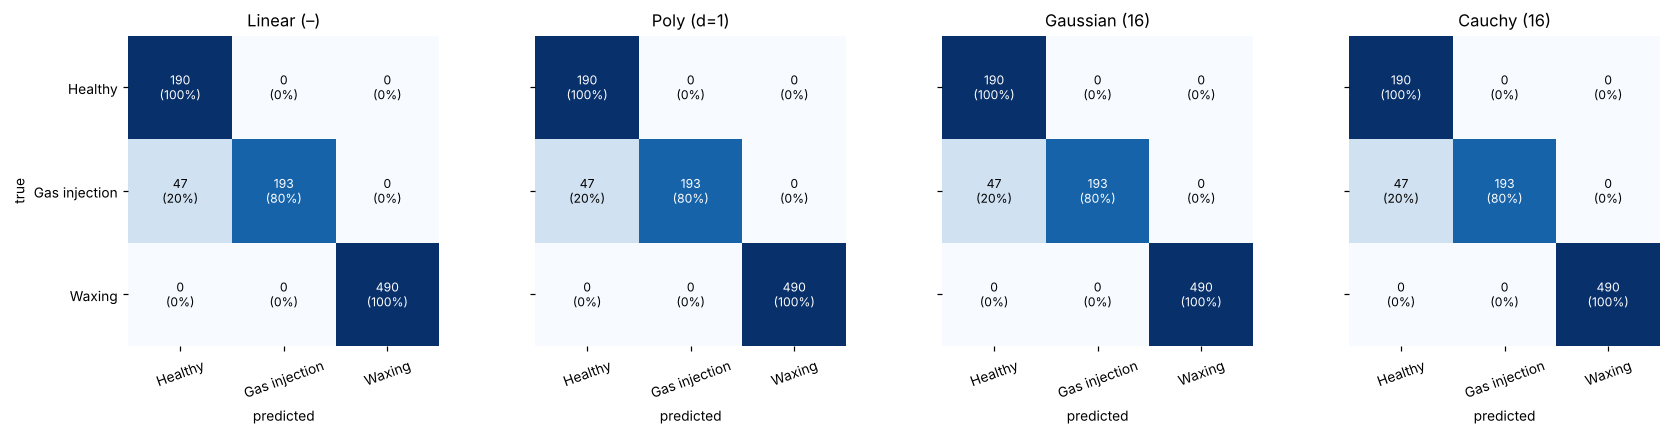

Samples misclassified by the chosen (linear) setting, with the number of repeats (of 10) they were wrong:
  row 36  Gas injection  group 16  flow 1.32 m/s  wrong 10x
  row 37  Gas injection  group 16  flow 1.32 m/s  wrong 10x
  row 38  Gas injection  group 16  flow 1.31 m/s  wrong 10x
  row 39  Gas injection  group 16  flow 1.30 m/s  wrong 10x
  row 40  Gas injection  group 16  flow 1.29 m/s  wrong 7x


In [10]:
names = [kt.CLASS_NAMES[c] for c in kt.CLASS_NAMES]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (kernel, label) in zip(axes, chosen.items()):
    C = cv[(kernel, label)]["conf"][2]
    share = C / C.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{C[i, j]}\n({share[i, j]:.0%})", ha="center", va="center", fontsize=8,
                    color="white" if share[i, j] > 0.6 else "black")
    ax.set_xticks(range(3), names, rotation=20)
    ax.set_yticks(range(3), names if ax is axes[0] else [])
    ax.set_xlabel("predicted")
    ax.set_title(f"{kernel} ({label})")
    ax.spines[:].set_visible(False)
axes[0].set_ylabel("true")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/m4_confusion.png")
plt.show()

lin = cv[("Linear", "–")]["wrong"]
print("Samples misclassified by the chosen (linear) setting, with the number of repeats (of 10) they were wrong:")
for i in np.where(lin > 0)[0]:
    print(f"  row {i + 1:2d}  {kt.CLASS_NAMES[y[i]]:<14} group {G[i]:2d}  flow {flow[i]:.2f} m/s  wrong {lin[i]}x")

## 11. How linear are the settings?
For a very large σ the Gaussian kernel becomes linear: $e^{-d^2/2\sigma^2} \approx 1 - d^2/2\sigma^2$, and
$-\lVert x-y \rVert^2/2 = x^\top y - (\lVert x \rVert^2 + \lVert y \rVert^2)/2$, whose last terms are removed by centring.
The same holds for the Cauchy kernel. To see where each setting lies, the table gives the absolute
correlation of kPC1–kPC3 (full data) with linear PC1–PC3: 1.000 means "the same as linear PCA".

In [11]:
T_lin, _, _, _ = kt.pca(Z_full)
print(f"{'kernel':<9}{'sigma/median':>13}   |corr| with linear PC1, PC2, PC3   acc q=2 (grouped)")
for kernel, kind in [("Gaussian", "rbf"), ("Cauchy", "cauchy")]:
    for f in factors[::-1]:
        S, _, _, _ = kt.kpca(kt.kernel_matrix(Z_full, kind, sigma=f * med_full))
        r = [abs(np.corrcoef(S[:, j], T_lin[:, j])[0, 1]) for j in range(3)]
        acc = cv[(kernel, f"{f:g}")]["scores"][2].mean()
        print(f"{kernel:<9}{f:>13g}   " + "  ".join(f"{v:.3f}" for v in r) + f"          {acc:.3f}")

kernel    sigma/median   |corr| with linear PC1, PC2, PC3   acc q=2 (grouped)
Gaussian            16   1.000  1.000  1.000          0.961
Gaussian             8   1.000  1.000  1.000          0.961
Gaussian             4   0.997  0.995  0.998          0.963
Gaussian             2   0.982  0.919  0.935          0.945
Gaussian             1   0.963  0.598  0.503          0.948
Gaussian           0.5   0.907  0.375  0.276          0.929
Gaussian          0.25   0.193  0.238  0.322          0.873
Gaussian         0.125   0.050  0.057  0.119          0.608
Gaussian        0.0625   0.041  0.021  0.074          0.452
Cauchy              16   1.000  1.000  1.000          0.961
Cauchy               8   0.997  0.996  0.998          0.963
Cauchy               4   0.986  0.951  0.962          0.950
Cauchy               2   0.971  0.716  0.677          0.962
Cauchy               1   0.953  0.469  0.320          0.943
Cauchy             0.5   0.906  0.354  0.365          0.939
Cauchy            0.25

## 12. Interpretation

**Checks.** Polynomial d = 1 reproduces the linear kernel exactly in every fold, no operating-point group
is ever split between training and test, every fold contains all three classes, and the same seed gives
the same result.

**Why grouped CV (sections 2 and 8).** Within each class, consecutive rows are far more alike than rows in
random order (for every class, none of 2000 random orderings is as close). With random CV these
near-duplicates fall on both sides of the split, which inflates the scores: linear PCA drops from 1.000
(random) to 0.961 (grouped) on two components, and small widths collapse much further (Gaussian at σ/8:
0.860 → 0.608). All conclusions below use grouped CV.

**Accuracy against the setting (sections 6–7).**
- **Large σ = linear PCA.** For σ ≥ 8 × median the Gaussian and Cauchy kernels give exactly the linear
  result (|corr| = 1.000 with PC1–PC3, section 11) and the same accuracy (0.961).
- **Moderate σ (0.5–4 × median)** gives 0.93–0.96 on two components, all within about two standard errors
  of linear PCA (SE ≈ 0.01, which understates the true uncertainty): equal within uncertainty.
- **Small σ fails.** Below a quarter of the median distance accuracy drops sharply (Gaussian 0.45 at σ/16):
  each sample is then only similar to itself, so the kPCs no longer describe groups, and a held-out operating
  point is not recognised. The heavy-tailed Cauchy kernel degrades more slowly (0.54 at σ/16).
- **Polynomial kernels** get worse with degree on two components (0.96 → 0.91 → 0.83 → 0.78 for
  d = 1–4); with three components d = 3 reaches 0.963, because kPC1 is then mostly the single extreme
  gas-injection sample and kPC2–kPC3 carry the class structure (notebook 03).

**What the selection rule chooses (section 9).** Every kernel reaches its best accuracy within one standard
error of 0.961, so the rule takes the smoothest setting: σ = 16 × median for Gaussian and Cauchy, d = 1 for
the polynomial kernel. These settings **are linear PCA**. The best Gaussian (σ = 4 × median, 0.963) and
Cauchy (σ = 8 × median, 0.963) are not meaningfully better.

**Where linear PCA fails (section 10).** The chosen (linear) setting misclassifies one whole operating point:
the low-flow gas-injection group (rows 36–40, 1.3 m/s) is predicted **healthy** whenever it is held out
(47 of 240 gas-injection predictions). Mild gas injection at a flow rate the model has not seen looks healthy
to linear PCA. Notebook 05 examines how the non-linear default settings handle this group.

## Summary – carried into Milestone 5
- With grouped CV, the honest accuracy of linear PCA on two components is 0.961, not 1.000.
- By the selection rule, every kernel still returns its linear limit; no kernel is significantly better
  than linear PCA overall. Polynomial kernels of degree ≥ 2 and small widths are worse.
- Linear PCA's errors are concentrated in one place: low-flow gas injection predicted as healthy.
